In [5]:
import pandas as pd
import glob
import os
import gc


# 1.  RUTAS

RUTA_CEN = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial\1000 simulaciones centralizado"
RUTA_DEC = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial\1000 Simulaciones DESCENTRALIZADO"
RUTA_SALIDA = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial"

print("🚀 INICIANDO CONSOLIDACIÓN SEPARADA (4 ARCHIVOS MAESTROS)...")


# 2. FUNCIÓN DE CONSOLIDACIÓN SEGURA

def consolidar_separado(ruta_origen, nombre_final, tipo_archivo):
    """
    ruta_origen: Carpeta donde buscar
    nombre_final: Nombre del archivo a crear (ej: MASTER_Centralizado_DETALLE.csv)
    tipo_archivo: 'Detalle' o 'Resumen'
    """
    archivo_salida = os.path.join(RUTA_SALIDA, nombre_final)
    
    # Limpieza inicial
    if os.path.exists(archivo_salida):
        os.remove(archivo_salida)
    
    print(f"\n🚜 Procesando: {nombre_final}...")
    
    # Buscar archivos recursivamente
    patron = os.path.join(ruta_origen, "**", f"Tesis_{tipo_archivo}_*.csv")
    archivos = glob.glob(patron, recursive=True)
    
    if not archivos:
        print(f"   ❌ No encontré archivos en {ruta_origen}")
        return

    print(f"   📦 Encontrados {len(archivos)} archivos. Uniendo...")
    
    # Escritura secuencial (Append) para no saturar memoria
    es_primero = True
    contador = 0
    
    for f in archivos:
        try:
            df = pd.read_csv(f)
            
            # Agregamos etiqueta por si acaso luego quieres juntarlos, pero ahora van separados
            if "Centralizado" in nombre_final:
                df['Escenario'] = 'Centralizado'
            else:
                df['Escenario'] = 'Descentralizado'
            
            # Guardar en disco
            modo = 'w' if es_primero else 'a'
            header = es_primero
            df.to_csv(archivo_salida, index=False, mode=modo, header=header)
            
            es_primero = False
            contador += 1
            
            # Liberar memoria
            del df
            gc.collect()
            
            if contador % 10 == 0:
                print(f"      -> Guardados {contador}/{len(archivos)}...")
                
        except Exception as e:
            print(f"      ⚠️ Error en {os.path.basename(f)}: {e}")
            
    print(f"   ✅ FINALIZADO: {nombre_final} creado exitosamente.")

# 3. EJECUCIÓN (Genera los 4 archivos)


# --- CASO CENTRALIZADO ---
consolidar_separado(RUTA_CEN, "MASTER_Centralizado_RESUMEN.csv", "Resumen")
consolidar_separado(RUTA_CEN, "MASTER_Centralizado_DETALLE.csv", "Detalle")

# --- CASO DESCENTRALIZADO ---
consolidar_separado(RUTA_DEC, "MASTER_Descentralizado_RESUMEN.csv", "Resumen")
consolidar_separado(RUTA_DEC, "MASTER_Descentralizado_DETALLE.csv", "Detalle")

print("\n🏁 TODO LISTO. Revisa tu carpeta principal.")

🚀 INICIANDO CONSOLIDACIÓN SEPARADA (4 ARCHIVOS MAESTROS)...

🚜 Procesando: MASTER_Centralizado_RESUMEN.csv...
   📦 Encontrados 3 archivos. Uniendo...
   ✅ FINALIZADO: MASTER_Centralizado_RESUMEN.csv creado exitosamente.

🚜 Procesando: MASTER_Centralizado_DETALLE.csv...
   📦 Encontrados 34 archivos. Uniendo...
      -> Guardados 10/34...
      -> Guardados 20/34...
      -> Guardados 30/34...
   ✅ FINALIZADO: MASTER_Centralizado_DETALLE.csv creado exitosamente.

🚜 Procesando: MASTER_Descentralizado_RESUMEN.csv...
   📦 Encontrados 2 archivos. Uniendo...
   ✅ FINALIZADO: MASTER_Descentralizado_RESUMEN.csv creado exitosamente.

🚜 Procesando: MASTER_Descentralizado_DETALLE.csv...
   📦 Encontrados 34 archivos. Uniendo...
      -> Guardados 10/34...
      -> Guardados 20/34...
      -> Guardados 30/34...
   ✅ FINALIZADO: MASTER_Descentralizado_DETALLE.csv creado exitosamente.

🏁 TODO LISTO. Revisa tu carpeta principal.


🚀 INICIANDO ANÁLISIS SEPARADO...
🚜 Procesando Centralizado (Lectura optimizada)...
🚜 Procesando Descentralizado (Lectura optimizada)...

📊 TABLA DE RESULTADOS POR SEDE (100% DATOS REALES):
   Sede_Origen   Pedidos  LeadTime_Avg  LeadTime_P95  Espera_Max  Costo_Viaje_Avg        Escenario
0        21951  18768468     24.180506         38.38      101.59         6.647169     Centralizado
1        46883  14073727     22.382528         31.96       55.96         6.865852     Centralizado
2        21951  16426633     23.333965         35.55       60.07         6.785622  Descentralizado
3        46883  16427815     23.768186         36.71       66.84         6.983328  Descentralizado

🎨 Generando Gráficos...

✅ ¡LISTO! Todo procesado sin errores de memoria.


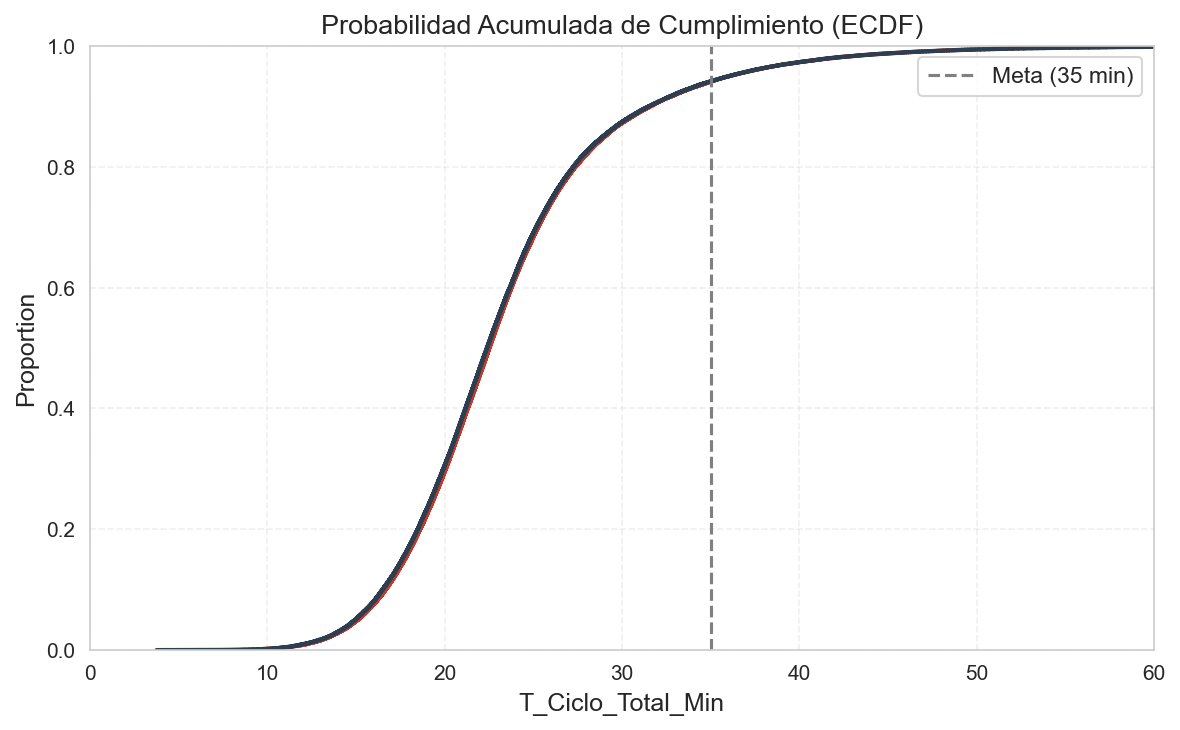

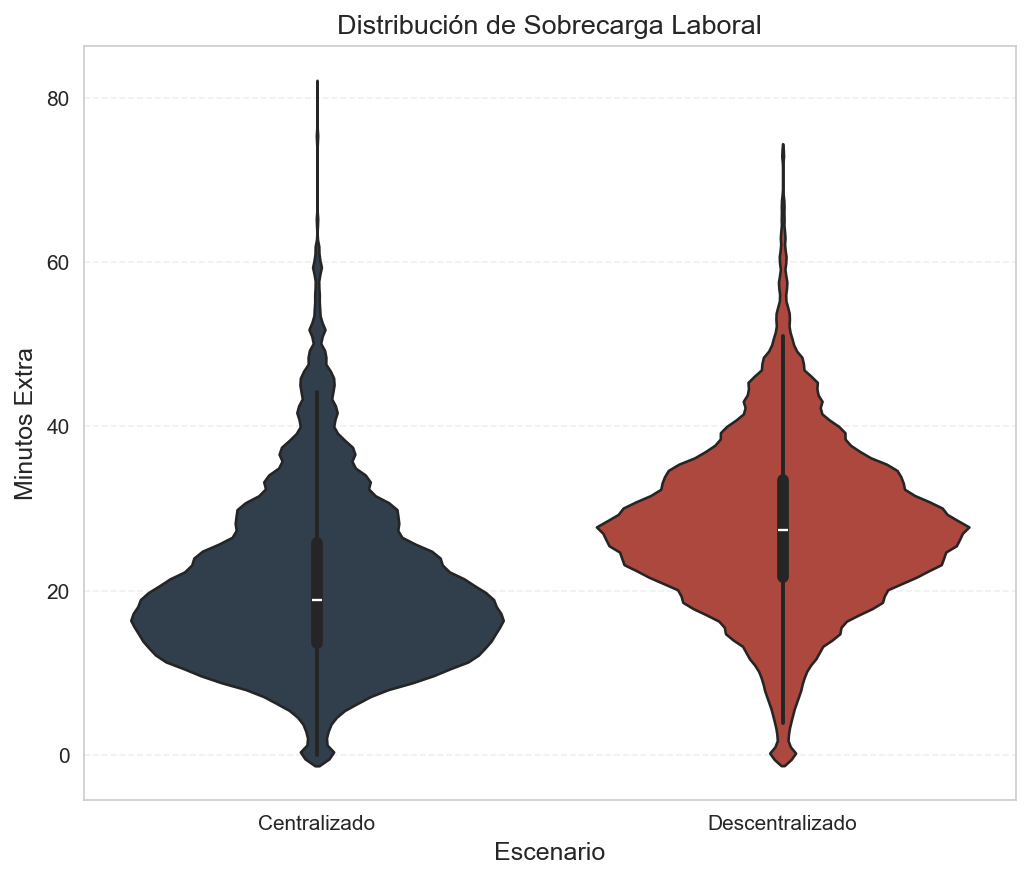

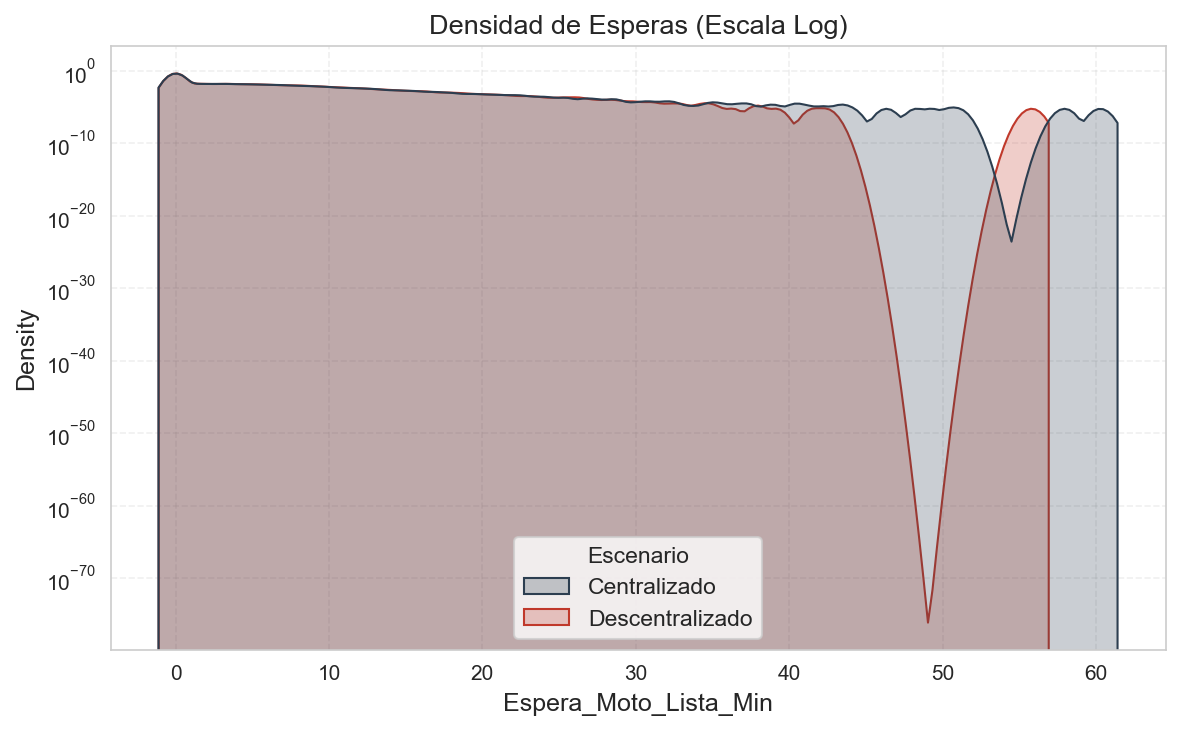

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import gc


# 1. CONFIGURACIÓN

RUTA_BASE = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial"
# Archivos Maestros (Asegúrate que los nombres sean correctos)
FILE_CEN = os.path.join(RUTA_BASE, "MASTER_Centralizado_DETALLE.csv")
FILE_DEC = os.path.join(RUTA_BASE, "MASTER_Descentralizado_DETALLE.csv")
FILE_RES_CEN = os.path.join(RUTA_BASE, "MASTER_Centralizado_RESUMEN.csv")
FILE_RES_DEC = os.path.join(RUTA_BASE, "MASTER_Descentralizado_RESUMEN.csv")

# Estilo de Gráficos (Paper Científico)
plt.rcParams.update({'font.size': 11, 'figure.dpi': 150, 'axes.grid': True})
PALETA = {'Centralizado': '#2c3e50', 'Descentralizado': '#c0392b'}


# 2. FUNCIÓN DE PROCESAMIENTO POR LOTES (Ahorra Memoria)

def procesar_escenario(ruta_archivo, nombre_escenario):
    print(f"🚜 Procesando {nombre_escenario} (Lectura optimizada)...")
    try:
        # Leemos solo lo necesario
        cols = ['Sede_Origen', 'T_Ciclo_Total_Min', 'Espera_Moto_Lista_Min', 'T_Viaje_Ida_Min']
        df = pd.read_csv(ruta_archivo, usecols=cols)
        
        # 1. Calculamos Estadísticas por Sede
        stats = df.groupby('Sede_Origen').agg(
            Pedidos=('T_Ciclo_Total_Min', 'count'),
            LeadTime_Avg=('T_Ciclo_Total_Min', 'mean'),
            LeadTime_P95=('T_Ciclo_Total_Min', lambda x: x.quantile(0.95)),
            Espera_Max=('Espera_Moto_Lista_Min', 'max'),
            Costo_Viaje_Avg=('T_Viaje_Ida_Min', 'mean')
        ).reset_index()
        stats['Escenario'] = nombre_escenario
        
        # 2. Extraemos Muestra para Gráficos (100k puntos)
        sample = df.sample(n=min(100000, len(df)), random_state=42)
        sample['Escenario'] = nombre_escenario
        
        # Limpieza de Memoria
        del df
        gc.collect()
        
        return stats, sample
        
    except Exception as e:
        print(f"❌ Error en {nombre_escenario}: {e}")
        return pd.DataFrame(), pd.DataFrame()


# 3. EJECUCIÓN SECUENCIAL

print("🚀 INICIANDO ANÁLISIS SEPARADO...")

# A. Centralizado
stats_cen, sample_cen = procesar_escenario(FILE_CEN, "Centralizado")

# B. Descentralizado
stats_dec, sample_dec = procesar_escenario(FILE_DEC, "Descentralizado")

# C. Combinar Resultados
if not stats_cen.empty and not stats_dec.empty:
    
    # Tabla Final de Estadísticas
    tabla_final = pd.concat([stats_cen, stats_dec], ignore_index=True)
    print("\n📊 TABLA DE RESULTADOS POR SEDE (100% DATOS REALES):")
    print(tabla_final.to_string())
    tabla_final.to_csv(os.path.join(RUTA_BASE, "Tesis_Tabla_Final_Sedes.csv"), index=False)
    
    # DataFrame para Gráficos (Solo Muestras)
    df_plot = pd.concat([sample_cen, sample_dec], ignore_index=True)
    
    # Cargar Resúmenes para Overtime (Son livianos, no hay problema)
    df_res = pd.concat([
        pd.read_csv(FILE_RES_CEN).assign(Escenario='Centralizado'),
        pd.read_csv(FILE_RES_DEC).assign(Escenario='Descentralizado')
    ], ignore_index=True)

   
    # 4. GRÁFICOS FINALES
  
    print("\n🎨 Generando Gráficos...")
    
    # Fig 1: ECDF Lead Time
    plt.figure(figsize=(8, 5))
    sns.ecdfplot(data=df_plot, x='T_Ciclo_Total_Min', hue='Escenario', palette=PALETA, linewidth=2)
    plt.axvline(35, color='gray', linestyle='--', label='Meta (35 min)')
    plt.title('Probabilidad Acumulada de Cumplimiento (ECDF)')
    plt.xlim(0, 60)
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(RUTA_BASE, "Fig1_ECDF.png"))
    
    # Fig 2: Violin Overtime
    plt.figure(figsize=(7, 6))
    sns.violinplot(data=df_res, x='Escenario', y='Overtime_Min', hue='Escenario', palette=PALETA, legend=False)
    plt.title('Distribución de Sobrecarga Laboral')
    plt.ylabel('Minutos Extra')
    plt.tight_layout()
    plt.savefig(os.path.join(RUTA_BASE, "Fig2_Violin.png"))
    
    # Fig 3: Esperas (Log)
    plt.figure(figsize=(8, 5))
    sns.kdeplot(data=df_plot, x='Espera_Moto_Lista_Min', hue='Escenario', palette=PALETA, fill=True)
    plt.yscale('log')
    plt.title('Densidad de Esperas (Escala Log)')
    plt.tight_layout()
    plt.savefig(os.path.join(RUTA_BASE, "Fig3_Esperas_Log.png"))
    
    print("\n✅ ¡LISTO! Todo procesado sin errores de memoria.")

else:
    print("❌ Falló la carga de datos. Revisa las rutas.")

🚀 INICIANDO ANÁLISIS FINAL...

📂 LEYENDO ESCENARIO: Centralizado...
   -> Resumen cargado (730000 días).
   -> Cargando Detalle (esto puede tardar unos segundos)...
   🧮 Calculando Estadísticas Reales (Población Total)...
   ✂️ Generando muestra representativa para gráficos...
   ✅ Memoria liberada.

📂 LEYENDO ESCENARIO: Descentralizado...
   -> Resumen cargado (730000 días).
   -> Cargando Detalle (esto puede tardar unos segundos)...
   🧮 Calculando Estadísticas Reales (Población Total)...
   ✂️ Generando muestra representativa para gráficos...
   ✅ Memoria liberada.

📄 Tabla Maestra guardada en: C:\Users\Tobias\Desktop\tesis simulacion geoespacial\Tesis_Tabla_KPIs_Final.csv
   Sede_Origen  Pedidos_Totales  LeadTime_Promedio  LeadTime_P95  Espera_Promedio  Espera_Max        Escenario
0        21951         18768468          24.180506         38.38         2.152147      101.59     Centralizado
1        46883         14073727          22.382528         31.96         0.955515       55.96

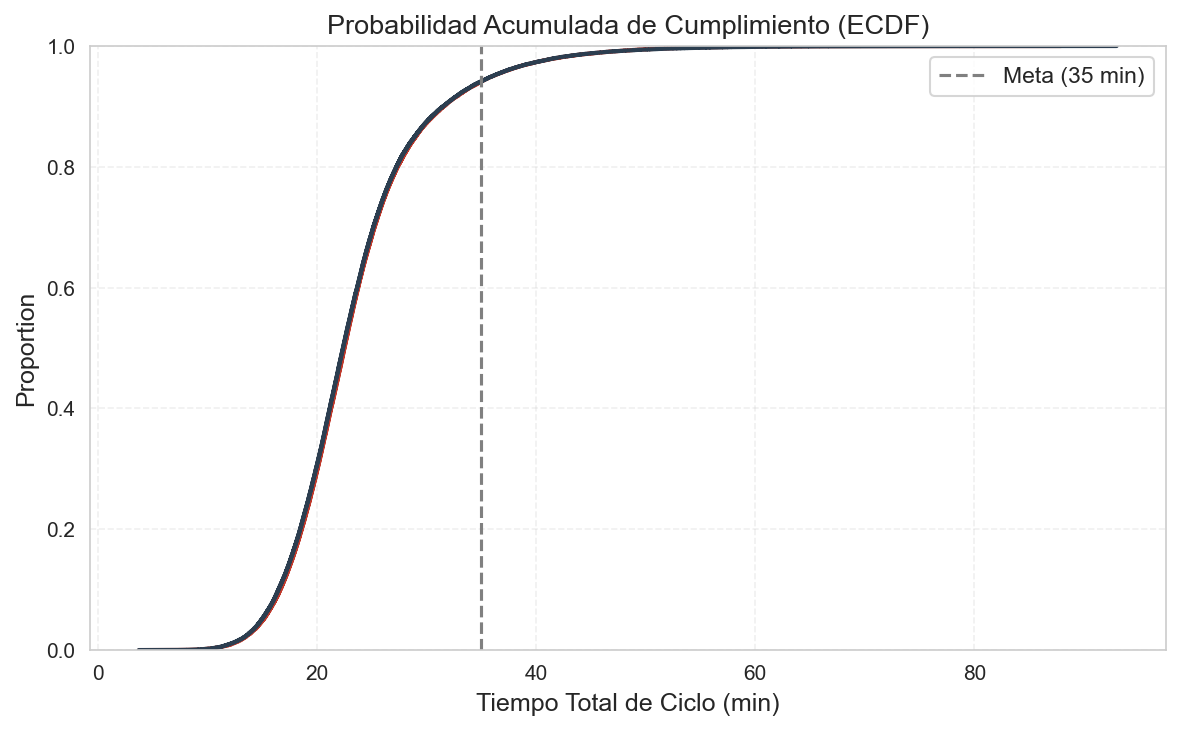

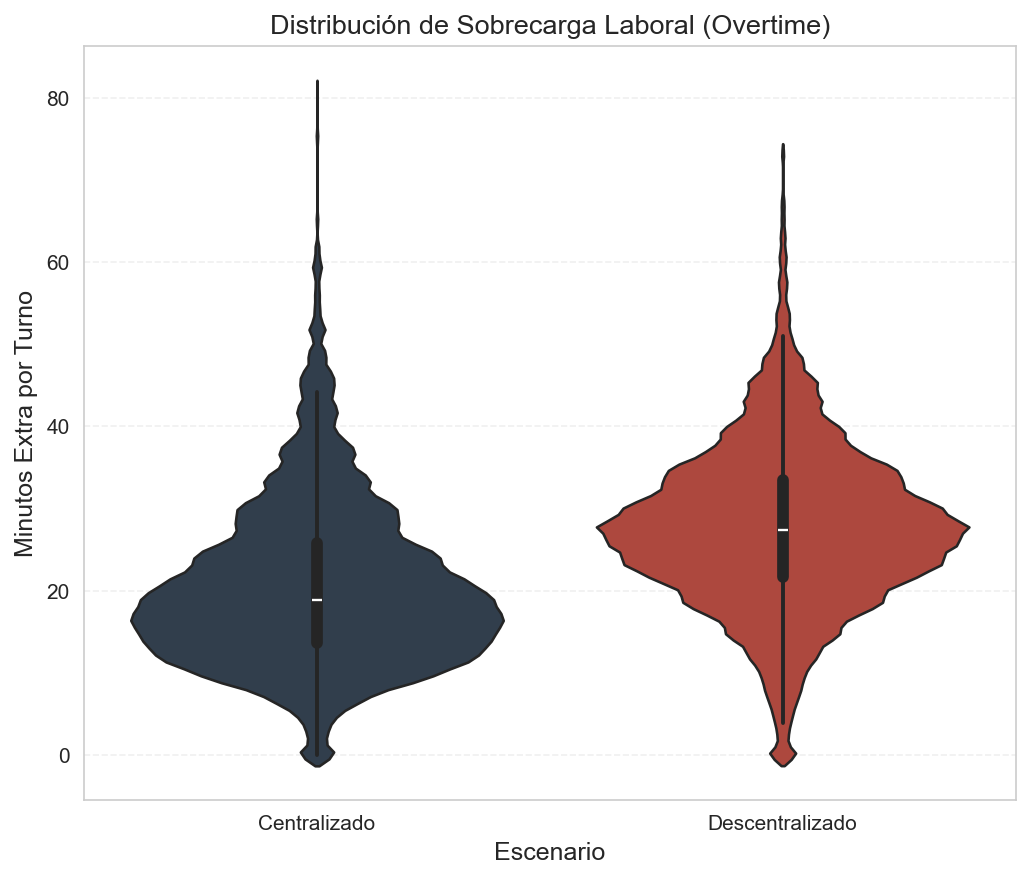

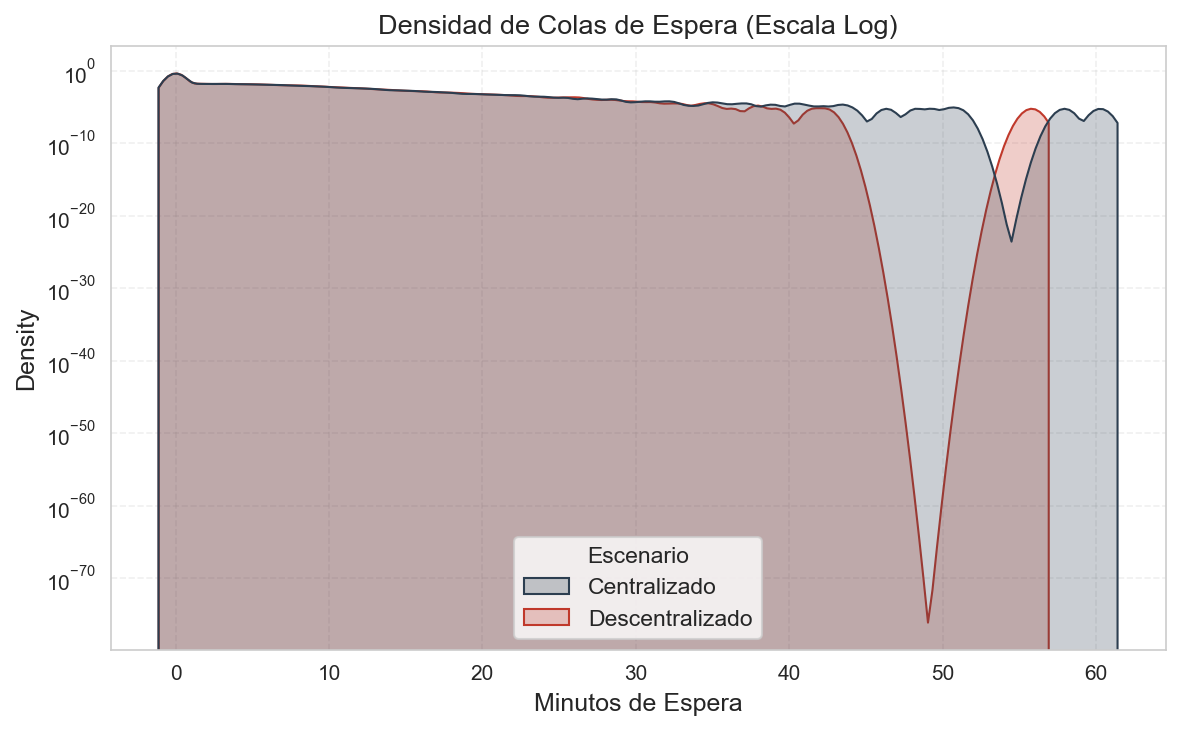

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import gc


# 1.  RUTAS 

BASE = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial"

# Definimos los 4 archivos exactos que ya creaste
FILE_CEN_DET = os.path.join(BASE, "MASTER_Centralizado_DETALLE.csv")
FILE_CEN_RES = os.path.join(BASE, "MASTER_Centralizado_RESUMEN.csv")

FILE_DEC_DET = os.path.join(BASE, "MASTER_Descentralizado_DETALLE.csv")
FILE_DEC_RES = os.path.join(BASE, "MASTER_Descentralizado_RESUMEN.csv")

# Configuración Visual para Tesis
plt.rcParams.update({'font.size': 11, 'figure.dpi': 150, 'axes.grid': True})
PALETA = {'Centralizado': '#2c3e50', 'Descentralizado': '#c0392b'} # Azul y Rojo serios


# 2. FUNCIÓN DE PROCESAMIENTO SECUENCIAL (Para no quemar la RAM)

def procesar_escenario_final(ruta_detalle, ruta_resumen, nombre_escenario):
    print(f"\n📂 LEYENDO ESCENARIO: {nombre_escenario}...")
    
    # 1. Cargar RESUMEN (Overtime) - Es liviano, cargamos todo
    df_res = pd.read_csv(ruta_resumen)
    df_res['Escenario'] = nombre_escenario
    print(f"   -> Resumen cargado ({len(df_res)} días).")

    # 2. Cargar DETALLE (Lead Time) - Es pesado, optimizamos
    print("   -> Cargando Detalle (esto puede tardar unos segundos)...")
    cols = ['Sede_Origen', 'T_Ciclo_Total_Min', 'Espera_Moto_Lista_Min', 'T_Viaje_Ida_Min']
    df_det = pd.read_csv(ruta_detalle, usecols=cols)
    
    # --- AUDITORÍA (Cálculo con el 100% de los datos) ---
    print("   🧮 Calculando Estadísticas Reales (Población Total)...")
    stats = df_det.groupby('Sede_Origen').agg(
        Pedidos_Totales=('T_Ciclo_Total_Min', 'count'),
        LeadTime_Promedio=('T_Ciclo_Total_Min', 'mean'),
        LeadTime_P95=('T_Ciclo_Total_Min', lambda x: x.quantile(0.95)),
        Espera_Promedio=('Espera_Moto_Lista_Min', 'mean'),
        Espera_Max=('Espera_Moto_Lista_Min', 'max')
    ).reset_index()
    stats['Escenario'] = nombre_escenario
    
    # --- MUESTREO (Solo para Gráficos) ---
    print("   ✂️ Generando muestra representativa para gráficos...")
    # Sacamos 100.000 puntos aleatorios. Es suficiente para HD.
    muestra = df_det.sample(n=min(100000, len(df_det)), random_state=42)
    muestra['Escenario'] = nombre_escenario
    
    # LIMPIEZA DE MEMORIA (Vital)
    del df_det
    gc.collect()
    print("   ✅ Memoria liberada.")
    
    return df_res, stats, muestra


# 3. EJECUCIÓN

print("🚀 INICIANDO ANÁLISIS FINAL...")

# Procesamos UNO POR UNO (Secuencial)
try:
    # A. Centralizado
    res_cen, stats_cen, plot_cen = procesar_escenario_final(FILE_CEN_DET, FILE_CEN_RES, "Centralizado")
    
    # B. Descentralizado
    res_dec, stats_dec, plot_dec = procesar_escenario_final(FILE_DEC_DET, FILE_DEC_RES, "Descentralizado")
    
    # C. Unificar Resultados
    df_res_final = pd.concat([res_cen, res_dec], ignore_index=True)
    df_stats_final = pd.concat([stats_cen, stats_dec], ignore_index=True)
    df_plot_final = pd.concat([plot_cen, plot_dec], ignore_index=True)

    
    # 4. RESULTADOS 

    
    # A. Guardar Tabla Excel (Datos 100% Reales)
    ruta_tabla = os.path.join(BASE, "Tesis_Tabla_KPIs_Final.csv")
    df_stats_final.to_csv(ruta_tabla, index=False)
    print(f"\n📄 Tabla Maestra guardada en: {ruta_tabla}")
    print(df_stats_final.to_string())

    # B. Generar Gráficos (Con la muestra representativa)
    print("\n🎨 Generando Gráficos Científicos...")
    
    # Fig 1: ECDF Lead Time
    plt.figure(figsize=(8, 5))
    sns.ecdfplot(data=df_plot_final, x='T_Ciclo_Total_Min', hue='Escenario', palette=PALETA, linewidth=2)
    plt.axvline(35, color='gray', linestyle='--', label='Meta (35 min)')
    plt.title('Probabilidad Acumulada de Cumplimiento (ECDF)')
    plt.xlabel('Tiempo Total de Ciclo (min)')
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(BASE, "Tesis_Fig1_LeadTime.png"))
    
    # Fig 2: Violin Plot Overtime
    plt.figure(figsize=(7, 6))
    sns.violinplot(data=df_res_final, x='Escenario', y='Overtime_Min', hue='Escenario', palette=PALETA, legend=False)
    plt.title('Distribución de Sobrecarga Laboral (Overtime)')
    plt.ylabel('Minutos Extra por Turno')
    plt.tight_layout()
    plt.savefig(os.path.join(BASE, "Tesis_Fig2_Overtime.png"))
    
    # Fig 3: Esperas (Escala Logarítmica)
    plt.figure(figsize=(8, 5))
    sns.kdeplot(data=df_plot_final, x='Espera_Moto_Lista_Min', hue='Escenario', palette=PALETA, fill=True)
    plt.yscale('log')
    plt.title('Densidad de Colas de Espera (Escala Log)')
    plt.xlabel('Minutos de Espera')
    plt.tight_layout()
    plt.savefig(os.path.join(BASE, "Tesis_Fig3_Esperas.png"))
    
    print("\n🏆 ¡PROCESO FINALIZADO CON ÉXITO! Revisa tu escritorio.")

except FileNotFoundError as e:
    print(f"\n❌ ERROR: No encontré uno de los archivos. Revisa que existan:\n{e}")
except Exception as e:
    print(f"\n❌ OCURRIÓ UN ERROR INESPERADO: {e}")

🚀 CARGANDO DATOS MASIVOS DE TIEMPO DE CICLO (100% POBLACIÓN)...
   -> Datos Centralizado cargados: 32,842,195 registros
   -> Datos Descentralizado cargados: 32,854,448 registros
✅ Gráfico Lead Time Total guardado.

🚀 CARGANDO DATOS MASIVOS DE OVERTIME (100% POBLACIÓN)...
✅ Gráfico Overtime Total guardado.

📊 GENERANDO TABLA ESTADÍSTICA FINAL...

          Variable       Escenario  N (Registros)  Media  Mediana  Std Dev   P95  Máximo
   Lead Time (min)    Centralizado       32842195  23.41    22.39     6.66 35.97  146.95
   Lead Time (min) Descentralizado       32854448  23.55    22.53     6.61 36.14  122.37
Overtime (min/día)    Centralizado         730000  20.59    18.87    10.00 39.62   80.80
Overtime (min/día) Descentralizado         730000  27.68    27.35     9.88 44.77   73.09
✅ Tabla guardada en CSV.


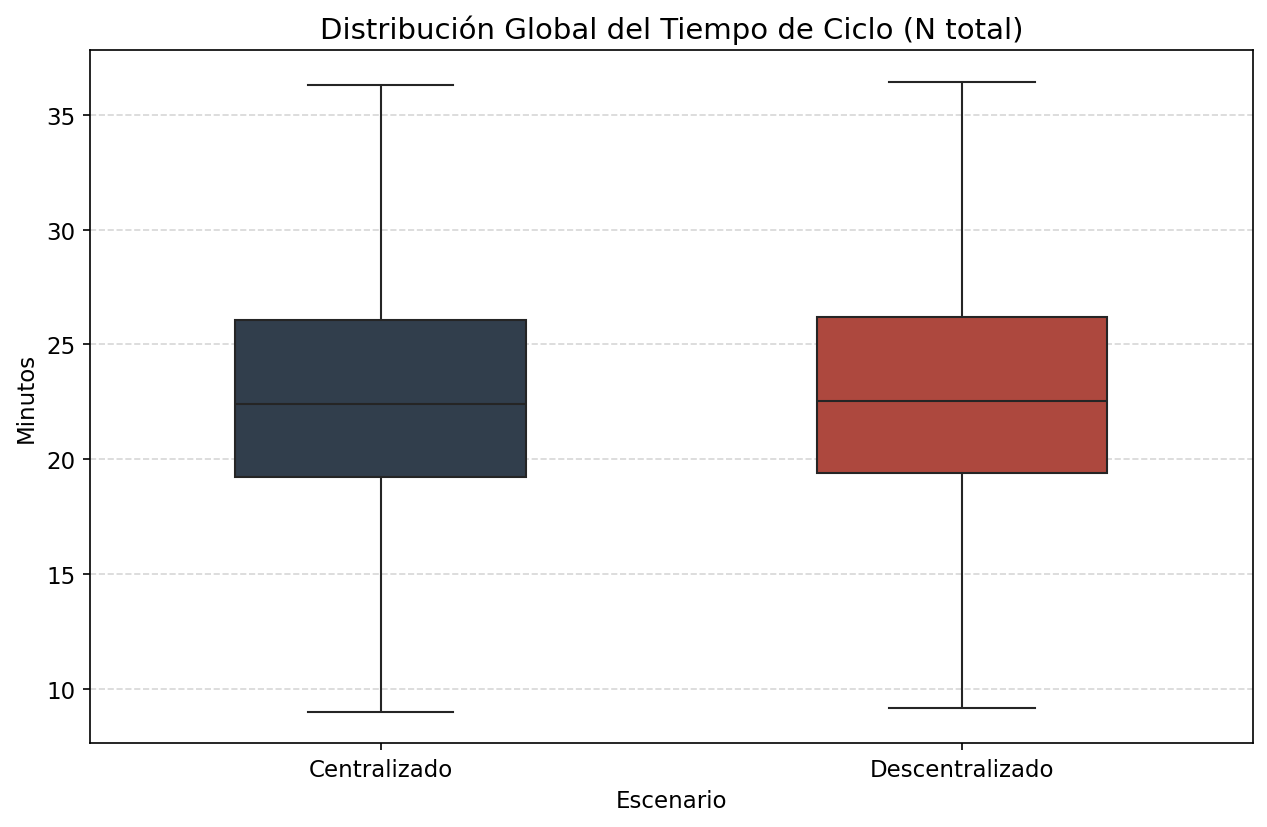

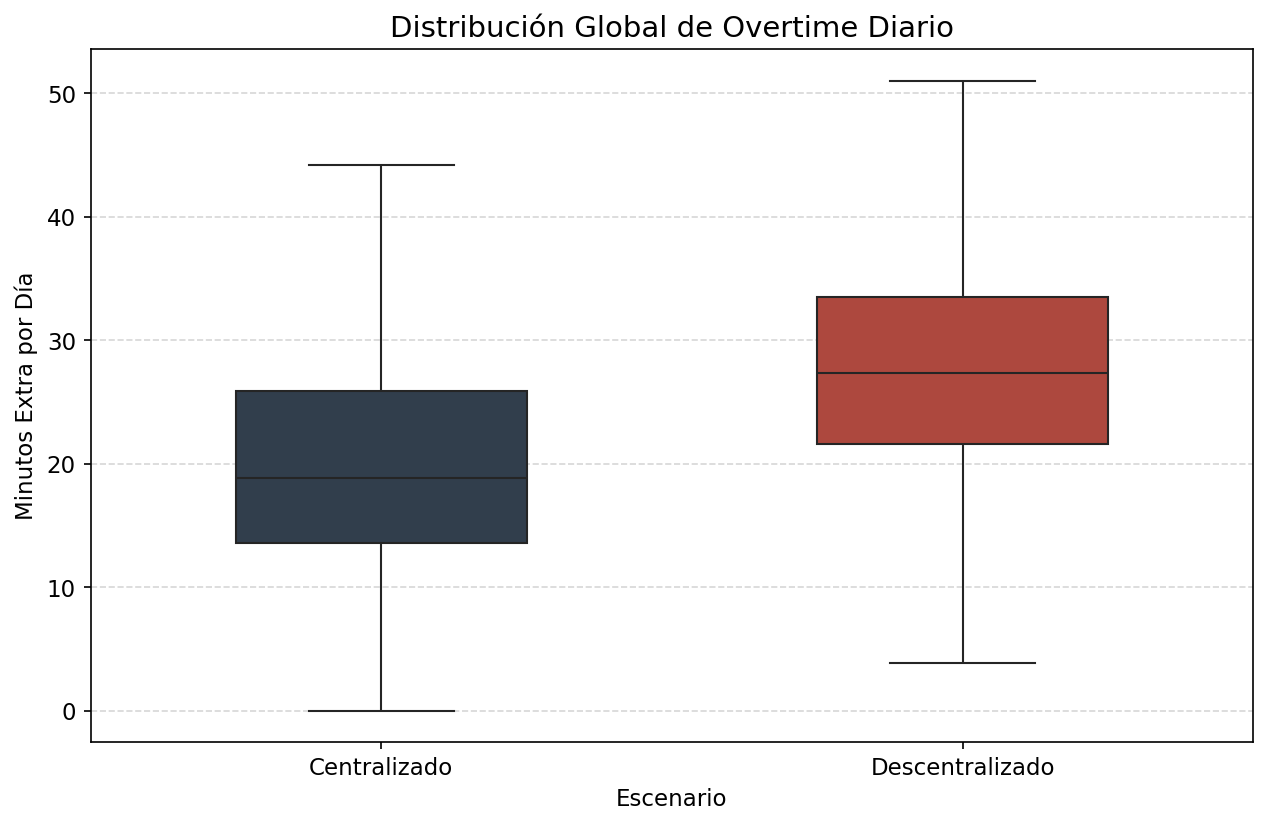

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import os
import gc  # Garbage Collector para limpiar RAM


# 1. CONFIGURACIÓN

# Ajusta tu ruta aquí
RUTA_BASE = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial"

FILE_CEN_DET = os.path.join(RUTA_BASE, "MASTER_Centralizado_DETALLE.csv")
FILE_DEC_DET = os.path.join(RUTA_BASE, "MASTER_Descentralizado_DETALLE.csv")
FILE_CEN_RES = os.path.join(RUTA_BASE, "MASTER_Centralizado_RESUMEN.csv")
FILE_DEC_RES = os.path.join(RUTA_BASE, "MASTER_Descentralizado_RESUMEN.csv")

# Paleta de colores UDP (Azul oscuro y Gris/Rojo)
PALETA = {'Centralizado': '#2c3e50', 'Descentralizado': '#c0392b'}


# 2. FUNCIÓN DE CARGA MASIVA (USANDO EL 100% DE DATOS)

def cargar_data_completa(ruta, columna):
    """
    Carga UNA sola columna de un archivo gigante para ahorrar memoria.
    Retorna la serie completa (sin muestreo).
    """
    if os.path.exists(ruta):
        # 'usecols' es el truco para cargar millones de filas sin que explote la RAM
        df = pd.read_csv(ruta, usecols=[columna])
        return df[columna]
    else:
        print(f"⚠️ Archivo no encontrado: {ruta}")
        return pd.Series(dtype=float)


# 3. ANÁLISIS 1: TIEMPO DE CICLO (LEAD TIME) - Archivos DETALLE

print("🚀 CARGANDO DATOS MASIVOS DE TIEMPO DE CICLO (100% POBLACIÓN)...")

# Cargar Series Completas
lead_cen = cargar_data_completa(FILE_CEN_DET, 'T_Ciclo_Total_Min')
lead_dec = cargar_data_completa(FILE_DEC_DET, 'T_Ciclo_Total_Min')

print(f"   -> Datos Centralizado cargados: {len(lead_cen):,} registros")
print(f"   -> Datos Descentralizado cargados: {len(lead_dec):,} registros")

# Crear DataFrame unificado solo para el gráfico (referencia)
# OJO: Para graficar "todo", concatenamos.
df_lead = pd.concat([
    pd.DataFrame({'Valor': lead_cen, 'Escenario': 'Centralizado'}),
    pd.DataFrame({'Valor': lead_dec, 'Escenario': 'Descentralizado'})
], ignore_index=True)

#  GRÁFICO 1: BOXPLOT DE TODA LA POBLACIÓN 
plt.figure(figsize=(10, 6))
# showfliers=False es la CLAVE. Usa todos los datos para la caja, 
# pero no dibuja los millones de puntitos negros externos.
sns.boxplot(data=df_lead, x='Escenario', y='Valor', hue='Escenario',
            palette=PALETA, showfliers=False, width=0.5)

plt.title('Distribución Global del Tiempo de Ciclo (N total)', fontsize=14)
plt.ylabel('Minutos')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.savefig(os.path.join(RUTA_BASE, "Grafico_LeadTime_TOTAL.png"), dpi=300)
print("✅ Gráfico Lead Time Total guardado.")

# Limpiar memoria RAM antes de seguir
del lead_cen, lead_dec, df_lead
gc.collect()


# ANÁLISIS 2: OVERTIME (HORAS EXTRA) - Archivos RESUMEN

print("\n🚀 CARGANDO DATOS MASIVOS DE OVERTIME (100% POBLACIÓN)...")

over_cen = cargar_data_completa(FILE_CEN_RES, 'Overtime_Min')
over_dec = cargar_data_completa(FILE_DEC_RES, 'Overtime_Min')

df_over = pd.concat([
    pd.DataFrame({'Valor': over_cen, 'Escenario': 'Centralizado'}),
    pd.DataFrame({'Valor': over_dec, 'Escenario': 'Descentralizado'})
], ignore_index=True)

# GRÁFICO 2: BOXPLOT OVERTIME 
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_over, x='Escenario', y='Valor', hue='Escenario',
            palette=PALETA, showfliers=False, width=0.5)

plt.title('Distribución Global de Overtime Diario', fontsize=14)
plt.ylabel('Minutos Extra por Día')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.savefig(os.path.join(RUTA_BASE, "Grafico_Overtime_TOTAL.png"), dpi=300)
print("✅ Gráfico Overtime Total guardado.")

# 
# 5. TABLA ESTADÍSTICA 
#
print("\n📊 GENERANDO TABLA.")

def get_stats(data, nombre, escenario):
    return {
        'Variable': nombre,
        'Escenario': escenario,
        'N (Registros)': len(data),
        'Media': data.mean(),
        'Mediana': data.median(),
        'Std Dev': data.std(),
        'P95': data.quantile(0.95),
        'Máximo': data.max()
    }

# Recargamos datos rápido para la tabla (ya que los borramos para liberar RAM)
lead_cen = cargar_data_completa(FILE_CEN_DET, 'T_Ciclo_Total_Min')
lead_dec = cargar_data_completa(FILE_DEC_DET, 'T_Ciclo_Total_Min')
over_cen = cargar_data_completa(FILE_CEN_RES, 'Overtime_Min')
over_dec = cargar_data_completa(FILE_DEC_RES, 'Overtime_Min')

resumen = [
    get_stats(lead_cen, 'Lead Time (min)', 'Centralizado'),
    get_stats(lead_dec, 'Lead Time (min)', 'Descentralizado'),
    get_stats(over_cen, 'Overtime (min/día)', 'Centralizado'),
    get_stats(over_dec, 'Overtime (min/día)', 'Descentralizado')
]

df_resumen = pd.DataFrame(resumen)
pd.options.display.float_format = '{:.2f}'.format

print("\n" + "="*80)
print(df_resumen.to_string(index=False))
print("="*80)

df_resumen.to_csv(os.path.join(RUTA_BASE, "Tabla_Final_Todas_Las_Estadisticas.csv"), index=False)
print("✅ Tabla guardada en CSV.")

In [9]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings


# 1. CONFIGURACIÓN INICIAL

warnings.filterwarnings('ignore') # Ignorar advertencias de versiones
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# 📂 !!! AJUSTA TU RUTA AQUÍ !!!
RUTA_BASE = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial"

# Colores Corporativos (Azul UDP / Rojo Contraste)
COLORS = ['#2c3e50', '#c0392b'] 
PALETA = {'Centralizado': COLORS[0], 'Descentralizado': COLORS[1]}

# Crear carpeta de salida
OUTPUT_DIR = os.path.join(RUTA_BASE, "RESULTADOS_FINALES_TESIS")
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"🚀 INICIANDO ANÁLISIS COMPLETO DE TESIS")
print(f"📂 Los resultados se guardarán en: {OUTPUT_DIR}\n")


# 2. FUNCIÓN DE ANÁLISIS (: Stats + Gráficos + Excel)

def analizar_kpi(nombre_kpi, archivo_cen, archivo_dec, columna, unidad, es_resumen=False):
    print(f"🔹 PROCESANDO KPI: {nombre_kpi.upper()}...")
    
    #  CARGA DE DATOS 
    try:
        # Si es archivo detalle (gigante), usamos usecols para ahorrar RAM
        if es_resumen:
            df_c = pd.read_csv(archivo_cen)
            df_d = pd.read_csv(archivo_dec)
        else:
            df_c = pd.read_csv(archivo_cen, usecols=[columna])
            df_d = pd.read_csv(archivo_dec, usecols=[columna])
            
        data_c = df_c[columna]
        data_d = df_d[columna]
        
        # Crear DF combinado para gráficos (muestreo si es gigante)
        if len(data_c) > 100000:
            sample_c = data_c.sample(50000, random_state=42)
            sample_d = data_d.sample(50000, random_state=42)
            print("   (Usando muestra representativa de 100k datos para gráficos ágiles)")
        else:
            sample_c = data_c
            sample_d = data_d
            
        df_plot = pd.concat([
            pd.DataFrame({'Valor': sample_c, 'Modo': 'Centralizado'}),
            pd.DataFrame({'Valor': sample_d, 'Modo': 'Descentralizado'})
        ])
        
    except Exception as e:
        print(f"❌ Error cargando archivos para {nombre_kpi}: {e}")
        return

    #  ESTADÍSTICA INFERENCIAL (T-Test) ---
    t_stat, p_value = stats.ttest_ind(data_c, data_d, equal_var=False)
    dif_media = data_c.mean() - data_d.mean()
    significancia = "✅ SIGNIFICATIVO (p<0.05)" if p_value < 0.05 else "❌ NO SIGNIFICATIVO"
    
    print(f"   📊 Media Cen: {data_c.mean():.2f} | Media Dec: {data_d.mean():.2f}")
    print(f"   📉 Diferencia: {dif_media:.2f} {unidad}")
    print(f"   🧪 T-Test p-value: {p_value:.2e} -> {significancia}")

    # --- C. GUARDAR TABLA ESTADÍSTICA ---
    stats_df = pd.DataFrame({
        'Escenario': ['Centralizado', 'Descentralizado'],
        'N': [len(data_c), len(data_d)],
        'Media': [data_c.mean(), data_d.mean()],
        'Std': [data_c.std(), data_d.std()],
        'Min': [data_c.min(), data_d.min()],
        'P25': [data_c.quantile(0.25), data_d.quantile(0.25)],
        'Mediana': [data_c.median(), data_d.median()],
        'P75': [data_c.quantile(0.75), data_d.quantile(0.75)],
        'P95': [data_c.quantile(0.95), data_d.quantile(0.95)],
        'Max': [data_c.max(), data_d.max()]
    })
    archivo_stats = os.path.join(OUTPUT_DIR, f"Tabla_Stats_{nombre_kpi.replace(' ', '_')}.csv")
    stats_df.to_csv(archivo_stats, index=False, float_format='%.2f')

    # --- D. GENERACIÓN DE GRÁFICOS ---
    
    # 1. BOXPLOT (Comparación de Distribución)
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=df_plot, x='Modo', y='Valor', hue='Modo', palette=PALETA, 
                showfliers=False, width=0.5, legend=False)
    sns.pointplot(data=df_plot, x='Modo', y='Valor', errorbar=None, 
                  color='white', markers='D', linestyle='none', markersize=5) # Media
    plt.title(f'Distribución de {nombre_kpi}', fontsize=14, fontweight='bold')
    plt.ylabel(f'{nombre_kpi} ({unidad})')
    plt.xlabel('')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"Grafico_Boxplot_{nombre_kpi.replace(' ', '_')}.png"), dpi=300)
    plt.close()

    # 2. BARRAS CON INTERVALOS DE CONFIANZA (IC 95%)
    plt.figure(figsize=(8, 6))
    medias = [data_c.mean(), data_d.mean()]
    # Error estándar * 1.96 para IC 95%
    errores = [1.96 * (data_c.std()/np.sqrt(len(data_c))), 1.96 * (data_d.std()/np.sqrt(len(data_d)))]
    
    bars = plt.bar(['Centralizado', 'Descentralizado'], medias, yerr=errores, 
                   capsize=10, color=COLORS, alpha=0.9, edgecolor='black')
    
    # Etiquetas de valor
    for bar, media in zip(bars, medias):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05*max(medias), 
                 f'{media:.2f}', ha='center', fontweight='bold', fontsize=12)
        
    plt.title(f'Promedio de {nombre_kpi} (con IC 95%)', fontsize=14, fontweight='bold')
    plt.ylabel(f'Promedio ({unidad})')
    plt.ylim(0, max(medias)*1.2)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"Grafico_BarrasIC_{nombre_kpi.replace(' ', '_')}.png"), dpi=300)
    plt.close()

    # 3. HISTOGRAMA DE DENSIDAD
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df_plot, x='Valor', hue='Modo', palette=PALETA, 
                 element="step", stat="density", common_norm=False, fill=True, alpha=0.3)
    plt.title(f'Histograma de Densidad - {nombre_kpi}', fontsize=14, fontweight='bold')
    plt.xlabel(f'{nombre_kpi} ({unidad})')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"Grafico_Histograma_{nombre_kpi.replace(' ', '_')}.png"), dpi=300)
    plt.close()
    
    print(f"   ✅ Gráficos y Tablas guardados.\n")


# 3. EJECUCIÓN SECUENCIAL


# Definir archivos
FILE_CEN_DET = os.path.join(RUTA_BASE, "MASTER_Centralizado_DETALLE.csv")
FILE_DEC_DET = os.path.join(RUTA_BASE, "MASTER_Descentralizado_DETALLE.csv")
FILE_CEN_RES = os.path.join(RUTA_BASE, "MASTER_Centralizado_RESUMEN.csv")
FILE_DEC_RES = os.path.join(RUTA_BASE, "MASTER_Descentralizado_RESUMEN.csv")

# 1. ANÁLISIS DE TIEMPO DE CICLO (LEAD TIME)
# Usa archivos DETALLE
analizar_kpi(
    nombre_kpi="Tiempo de Ciclo Total",
    archivo_cen=FILE_CEN_DET,
    archivo_dec=FILE_DEC_DET,
    columna="T_Ciclo_Total_Min",
    unidad="min",
    es_resumen=False
)

# 2. ANÁLISIS DE ESPERA MOTORISTA
# Usa archivos DETALLE
analizar_kpi(
    nombre_kpi="Espera Motorista",
    archivo_cen=FILE_CEN_DET,
    archivo_dec=FILE_DEC_DET,
    columna="Espera_Moto_Lista_Min",
    unidad="min",
    es_resumen=False
)

# 3. ANÁLISIS DE OVERTIME (HORAS EXTRA)
# Usa archivos RESUMEN (Importante: aquí la unidad es min/día)
analizar_kpi(
    nombre_kpi="Overtime Diario",
    archivo_cen=FILE_CEN_RES,
    archivo_dec=FILE_DEC_RES,
    columna="Overtime_Min",
    unidad="min/día",
    es_resumen=True
)

print("🏆 ¡PROCESO COMPLETADO EXITOSAMENTE!")
print("   Revisa la carpeta 'RESULTADOS_FINALES_TESIS' en tu escritorio.")

🚀 INICIANDO ANÁLISIS COMPLETO DE TESIS
📂 Los resultados se guardarán en: C:\Users\Tobias\Desktop\tesis simulacion geoespacial\RESULTADOS_FINALES_TESIS

🔹 PROCESANDO KPI: TIEMPO DE CICLO TOTAL...
   (Usando muestra representativa de 100k datos para gráficos ágiles)
   📊 Media Cen: 23.41 | Media Dec: 23.55
   📉 Diferencia: -0.14 min
   🧪 T-Test p-value: 0.00e+00 -> ✅ SIGNIFICATIVO (p<0.05)
   ✅ Gráficos y Tablas guardados.

🔹 PROCESANDO KPI: ESPERA MOTORISTA...
   (Usando muestra representativa de 100k datos para gráficos ágiles)
   📊 Media Cen: 1.64 | Media Dec: 1.67
   📉 Diferencia: -0.03 min
   🧪 T-Test p-value: 3.50e-201 -> ✅ SIGNIFICATIVO (p<0.05)
   ✅ Gráficos y Tablas guardados.

🔹 PROCESANDO KPI: OVERTIME DIARIO...
   (Usando muestra representativa de 100k datos para gráficos ágiles)
   📊 Media Cen: 20.59 | Media Dec: 27.68
   📉 Diferencia: -7.09 min/día
   🧪 T-Test p-value: 0.00e+00 -> ✅ SIGNIFICATIVO (p<0.05)
   ✅ Gráficos y Tablas guardados.

🏆 ¡PROCESO COMPLETADO EXITOSAMENTE

In [3]:
import pandas as pd
import numpy as np
from scipy import stats
import os


# 1. CONFIGURACIÓN DE RUTAS

ruta_base = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial"
archivo_res_cen = os.path.join(ruta_base, "MASTER_Centralizado_RESUMEN.csv")
archivo_res_dec = os.path.join(ruta_base, "MASTER_Descentralizado_RESUMEN.csv")


# 2. FUNCIÓN DE PROCESAMIENTO (AGRUPACIÓN CORRECTA)

def procesar_resumen(ruta, escenario):
    print(f"📥 Procesando escenario: {escenario}...")
    
    # Cargamos el archivo completo (aprox 730,000 filas por año/réplicas)
    df = pd.read_csv(ruta)
    
    #  Agrupar por Replica Y Sede
    resumen_sede = df.groupby(["Replica", "Sede"]).agg({
        "Total_Pedidos": "sum",       # Queremos saber el TOTAL de pedidos del año
        "Overtime_Min": "mean",       # Queremos saber el PROMEDIO DIARIO de overtime en ese año
        "Horas_Turno": "first"        # Rescatamos el dato del turno
    }).reset_index()
    
    resumen_sede["Escenario"] = escenario
    
    # Calcular métrica de productividad extra
    # Pedidos por hora totales en el año (asumiendo 365 días)
    resumen_sede["Pedidos_por_Hora"] = resumen_sede["Total_Pedidos"] / (resumen_sede["Horas_Turno"] * 365)
    
    print(f"   ✅ Filas generadas: {len(resumen_sede)} (Aprox. 1000 por cada Sede)")
    return resumen_sede


# 3. EJECUCIÓN

print("🚀 INICIANDO ANÁLISIS DE OVERTIME...\n")

df_cen = procesar_resumen(archivo_res_cen, "Centralizado")
df_dec = procesar_resumen(archivo_res_dec, "Descentralizado")

# Unimos todo en un  DataFrame de ~4000 filas (2 escenarios x 2 sedes x 1000 réplicas)
df_final = pd.concat([df_cen, df_dec], ignore_index=True)

# Convertir el ID de la Sede a texto para que sea más fácil de leer en los gráficos
df_final["Sede"] = df_final["Sede"].astype(str)


# 4. TABLA RESUMEN PARA LA TESIS 

print("\n" + ""*80)
print("📊 RESUMEN DE IMPACTO: OVERTIME POR SEDE")
print(""*80)

# Hacemos una tabla  para ver el comportamiento promedio de las 1000 réplicas
tabla_kpi = df_final.groupby(["Escenario", "Sede"]).agg({
    "Overtime_Min": ["mean", "max", "std"], # Media, Peor Caso, y Desviación (Estabilidad)
    "Total_Pedidos": "mean"                 # Pedidos anuales promedio
}).round(2)

print(tabla_kpi)
print("="*80)


# 5. EXPORTAR RESULTADOS 

ruta_export = os.path.join(ruta_base, "Resultados_Overtime_Por_Sede.csv")
df_final.to_csv(ruta_export, index=False)

print(f"\n💾 Archivo guardado exitosamente:")
print(f"   -> {ruta_export}")
print("   (Este archivo contiene las filas exactas agrupadas por Réplica y Sede)")

🚀 INICIANDO ANÁLISIS DE OVERTIME...

📥 Procesando escenario: Centralizado...
   ✅ Filas generadas: 2000 (Aprox. 1000 por cada Sede)
📥 Procesando escenario: Descentralizado...
   ✅ Filas generadas: 2000 (Aprox. 1000 por cada Sede)

📊 RESUMEN DE IMPACTO: OVERTIME POR SEDE
                      Overtime_Min              Total_Pedidos
                              mean    max   std          mean
Escenario       Sede                                         
Centralizado    21951        24.68  67.05  9.00      18768.47
                46883        16.50  49.83  5.76      14073.73
Descentralizado 21951        26.42  54.50  5.91      16426.63
                46883        28.94  63.13  6.34      16427.81

💾 Archivo guardado exitosamente:
   -> C:\Users\Tobias\Desktop\tesis simulacion geoespacial\Resultados_Overtime_Por_Sede.csv
   (Este archivo contiene las filas exactas agrupadas por Réplica y Sede)


Análisis Estadístico de Overtime por Sucursal

TABLA 1: INTERVALOS DE CONFIANZA AL 95%
      Escenario  Sede  Media_Overtime  IC_95_Inferior  IC_95_Superior
   Centralizado 21951           24.68           24.12           25.24
   Centralizado 46883           16.50           16.14           16.86
Descentralizado 21951           26.42           26.06           26.79
Descentralizado 46883           28.94           28.55           29.33


TABLA 2: PRUEBA T DE STUDENT (WELCH) PARA MUESTRAS INDEPENDIENTES
 Sede  Reduccion_Minutos Reduccion_Porcentual  Estadistico_T   P_Value
21951               1.75                6.61%          -5.13  3.28e-07
46883              12.44               42.99%         -45.96 1.78e-314


Gráfico exportado en: C:\Users\Tobias\Desktop\tesis simulacion geoespacial\Grafico_Overtime_IC95.png


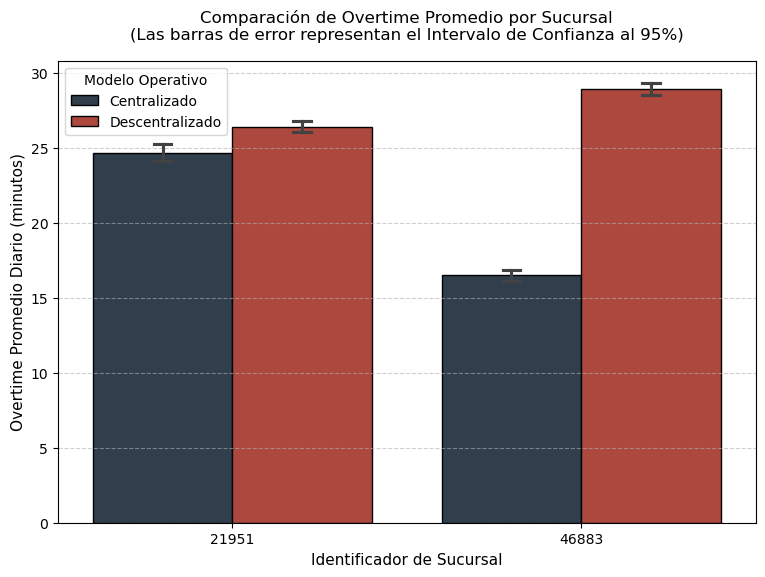

In [13]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. CARGA DE DATOS
ruta_base = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial"
archivo_datos = os.path.join(ruta_base, "Resultados_Overtime_Por_Sede.csv")

df = pd.read_csv(archivo_datos, sep=';') 
df["Sede"] = df["Sede"].astype(str)

print("Análisis Estadístico de Overtime por Sucursal\n")

# 2. TABLA 1: INTERVALOS DE CONFIANZA (95%)
def calcular_ic_95(data):
    n = len(data)
    media = np.mean(data)
    std = np.std(data, ddof=1)
    error_estandar = std / np.sqrt(n)
    margen_error = stats.t.ppf(0.975, n-1) * error_estandar
    return media, media - margen_error, media + margen_error

resultados_ic = []
for (escenario, sede), grupo in df.groupby(["Escenario", "Sede"]):
    media, li, ls = calcular_ic_95(grupo["Overtime_Min"])
    resultados_ic.append({
        "Escenario": escenario,
        "Sede": sede,
        "Media_Overtime": media,
        "IC_95_Inferior": li,
        "IC_95_Superior": ls
    })

df_ic = pd.DataFrame(resultados_ic).round(2)

print("TABLA 1: INTERVALOS DE CONFIANZA AL 95%")
print(df_ic.to_string(index=False))
print("\n")

# 3. TABLA 2: PRUEBA DE HIPÓTESIS (T-TEST DE WELCH)
resultados_ttest = []
for sede in df["Sede"].unique():
    data_cen = df[(df["Sede"] == sede) & (df["Escenario"] == "Centralizado")]["Overtime_Min"]
    data_dec = df[(df["Sede"] == sede) & (df["Escenario"] == "Descentralizado")]["Overtime_Min"]
    
    t_stat, p_val = stats.ttest_ind(data_cen, data_dec, equal_var=False)
    
    reduccion_min = data_dec.mean() - data_cen.mean()
    reduccion_pct = (reduccion_min / data_dec.mean()) * 100
    
    resultados_ttest.append({
        "Sede": sede,
        "Reduccion_Minutos": reduccion_min,
        "Reduccion_Porcentual": reduccion_pct,
        "Estadistico_T": t_stat,
        "P_Value": p_val
    })

df_ttest = pd.DataFrame(resultados_ttest)
df_ttest["Reduccion_Minutos"] = df_ttest["Reduccion_Minutos"].round(2)
df_ttest["Reduccion_Porcentual"] = df_ttest["Reduccion_Porcentual"].round(2).astype(str) + "%"
# Formateo científico para el p-value para que se vea académico
df_ttest["P_Value"] = df_ttest["P_Value"].apply(lambda x: f"{x:.2e}")
df_ttest["Estadistico_T"] = df_ttest["Estadistico_T"].round(2)

print("TABLA 2: PRUEBA T DE STUDENT (WELCH) PARA MUESTRAS INDEPENDIENTES")
print(df_ttest.to_string(index=False))
print("\n")

# 4. GENERACIÓN DEL GRÁFICO
plt.figure(figsize=(9, 6))

sns.barplot(data=df, x="Sede", y="Overtime_Min", hue="Escenario", 
            palette={'Centralizado': '#2c3e50', 'Descentralizado': '#c0392b'},
            capsize=0.1, errorbar=('ci', 95), edgecolor='black')

plt.title("Comparación de Overtime Promedio por Sucursal\n(Las barras de error representan el Intervalo de Confianza al 95%)", 
          fontsize=12, pad=15)
plt.ylabel("Overtime Promedio Diario (minutos)", fontsize=11)
plt.xlabel("Identificador de Sucursal", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title="Modelo Operativo", title_fontsize='10')

ruta_grafico = os.path.join(ruta_base, "Grafico_Overtime_IC95.png")
plt.savefig(ruta_grafico, dpi=300, bbox_inches='tight')
print(f"Gráfico exportado en: {ruta_grafico}")

El gráfico ha sido actualizado y guardado exitosamente en:
C:\Users\Tobias\Desktop\tesis simulacion geoespacial\Grafico_Overtime_Tesis.png


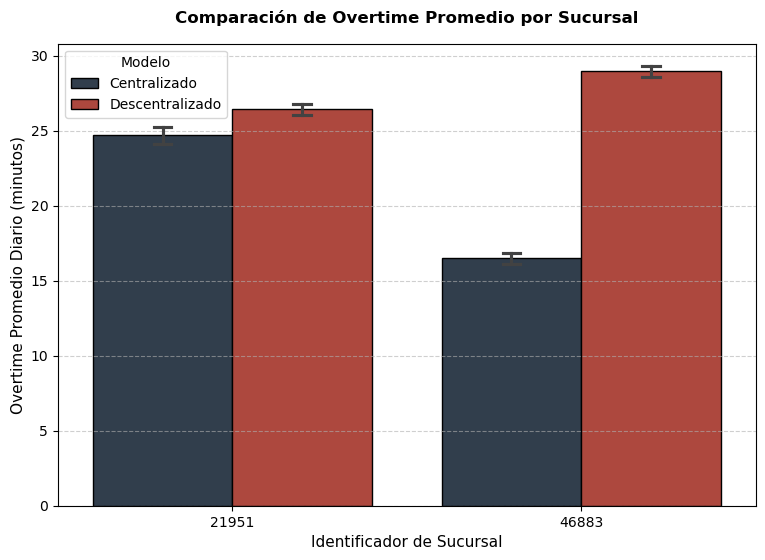

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Rutas y carga de datos
ruta_base = r"C:\Users\Tobias\Desktop\tesis simulacion geoespacial"
archivo_datos = os.path.join(ruta_base, "Resultados_Overtime_Por_Sede.csv")

df = pd.read_csv(archivo_datos, sep=';') 
df["Sede"] = df["Sede"].astype(str)

# Configuración del lienzo
plt.figure(figsize=(9, 6))

# Gráfico con Intervalos de Confianza
sns.barplot(data=df, x="Sede", y="Overtime_Min", hue="Escenario", 
            palette={'Centralizado': '#2c3e50', 'Descentralizado': '#c0392b'},
            capsize=0.1, errorbar=('ci', 95), edgecolor='black')

# Títulos limpios y formales
plt.title("Comparación de Overtime Promedio por Sucursal", fontsize=12, pad=15, fontweight='bold')
plt.ylabel("Overtime Promedio Diario (minutos)", fontsize=11)
plt.xlabel("Identificador de Sucursal", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Leyenda ajustada
plt.legend(title="Modelo", title_fontsize='10')

# Guardar archivo descargable en su escritorio
ruta_grafico = os.path.join(ruta_base, "Grafico_Overtime_Tesis.png")
plt.savefig(ruta_grafico, dpi=300, bbox_inches='tight')

print(f"El gráfico ha sido actualizado y guardado exitosamente en:\n{ruta_grafico}")

In [1]:
import pandas as pd
from scipy.stats import mannwhitneyu

# 1. Cargar tus datos (Asegúrate de que los archivos estén en la misma carpeta)
df_cent = pd.read_csv('MASTER_Centralizado_RESUMEN.csv')
df_desc = pd.read_csv('MASTER_Descentralizado_RESUMEN.csv')

# 2. Preparar el formato de la tabla
print("| Instalación | Mediana Descentralizado | Mediana Centralizado | Estadístico U | P-Value | Decisión |")
print("|---|---|---|---|---|---|")

# 3. Calcular para cada Sede
for sede in [46883, 21951]:
    overtime_cent = df_cent[df_cent['Sede'] == sede]['Overtime_Min']
    overtime_desc = df_desc[df_desc['Sede'] == sede]['Overtime_Min']
    
    # Prueba Mann-Whitney
    u_stat, p_value = mannwhitneyu(overtime_desc, overtime_cent, alternative='two-sided')
    
    # Formatear P-Value para que no salga un chorrero de ceros
    if p_value < 0.001:
        p_str = "< 0.001"
    else:
        p_str = f"{p_value:.4f}"
        
    decision = "Rechaza H0" if p_value < 0.05 else "No Rechaza H0"
    
    # Imprimir fila de la tabla
    print(f"| Sede {sede} | {overtime_desc.median():.2f} min | {overtime_cent.median():.2f} min | {u_stat:.2e} | {p_str} | {decision} |")

print("\n(Nota: Puedes copiar esta tabla directamente y pegarla en Word o Markdown)")

| Instalación | Mediana Descentralizado | Mediana Centralizado | Estadístico U | P-Value | Decisión |
|---|---|---|---|---|---|
| Sede 46883 | 28.38 min | 15.72 min | 1.14e+11 | < 0.001 | Rechaza H0 |
| Sede 21951 | 26.03 min | 23.33 min | 7.58e+10 | < 0.001 | Rechaza H0 |

(Nota: Puedes copiar esta tabla directamente y pegarla en Word o Markdown)


In [1]:
import pandas as pd

print("Procesando datos de Overtime...")

# 1. Cargar los archivos que subiste
df_cent_res = pd.read_csv('MASTER_Centralizado_RESUMEN.csv')
df_desc_res = pd.read_csv('MASTER_Descentralizado_RESUMEN.csv')

# 2. Unir ambos archivos en uno solo
df_all_overtime = pd.concat([df_cent_res, df_desc_res])

# 3. Calcular el promedio de Overtime por Sede y por Escenario
resumen_overtime = df_all_overtime.groupby(['Sede', 'Escenario'])['Overtime_Min'].mean().reset_index()

# 4. Exportar a un CSV limpio para Excel
resumen_overtime.to_csv('Excel_Graficos_Overtime.csv', index=False)

print("-> Archivo 'Excel_Graficos_Overtime.csv' creado con éxito. Ya puedes abrirlo en Excel.")

Procesando datos de Overtime...
-> Archivo 'Excel_Graficos_Overtime.csv' creado con éxito. Ya puedes abrirlo en Excel.
